<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/31_expansion_eva_vs_mapbiomas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 31 · Palma de aceite: EVA frente a MapBiomas

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿la EVA y MapBiomas cuentan la misma historia de la palma de aceite en la Altillanura?

**Entradas:**
- EVA: `modulos/expansion/datos/eva/eva_altillanura_anual.csv` (Git), cultivo `PALMA DE ACEITE`, área sembrada y cosechada.
- MapBiomas Colombia, Colección 3: `modulos/expansion/datos/mapbiomas_crudos/` (Git), clase de nivel 2 "Palm oil".

**Salidas:**
- `modulos/expansion/resultados/31_palma_eva_mapbiomas.csv`: una fila por municipio y año.
- `modulos/expansion/resultados/31_palma_resumen.csv`: Spearman y sesgo por grupo.
- `modulos/expansion/graficas/31_palma_eva_vs_mapbiomas.png`.

**Método:**
- Años comunes de las dos fuentes, desde el primer año en que la EVA reporta palma. Si un municipio reporta otros cultivos en la EVA un año pero no palma, su palma de la EVA es 0; si no reporta nada ese año, ese municipio-año queda fuera.
- Se comparan los municipio-año en que al menos una de las dos fuentes tiene palma.
- **Spearman** (ρ): si las dos fuentes ordenan igual los municipio-año. Se calcula con todos los municipio-año, con la serie regional anual y dentro de cada municipio.
- **Sesgo medio**: promedio de EVA − MapBiomas, en hectáreas, y sesgo relativo = suma de EVA − MapBiomas sobre la suma de MapBiomas, en %.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats

print('Raíz del repo:', RAIZ)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto


## Paso 2. Palma en las dos fuentes

In [2]:
partes = []
for ruta in sorted(glob.glob(os.path.join(CRUDOS, '*.csv'))):
    mb = pd.read_csv(ruta, encoding='utf-8-sig')
    mb['Level 2'] = mb['Level 2'].fillna('').str.strip()
    mb = mb[mb['Level 2'] != '']
    largo = mb.melt(id_vars=['Level 1', 'Level 2'], var_name='anio', value_name='ha')
    largo['anio'] = largo['anio'].astype(int)
    largo['ha'] = pd.to_numeric(largo['ha'], errors='coerce').fillna(0.0)
    largo['mpio_cdpmp'] = re.search(r'(\d{5})_', os.path.basename(ruta)).group(1)
    partes.append(largo)
mb = pd.concat(partes, ignore_index=True)
assert mb['mpio_cdpmp'].nunique() == 7

nombres = (pd.read_csv(os.path.join(COMUNES, 'altillanura_municipios.csv'), dtype={'mpio_cdpmp': str})
           .set_index('mpio_cdpmp')['mpio_cnmbr'])

mb_palma = (mb[mb['Level 2'] == 'Palm oil'].groupby(['mpio_cdpmp', 'anio'])['ha'].sum()
            .rename('mapbiomas_ha'))

eva = pd.read_csv(os.path.join(EXPANSION, 'datos', 'eva', 'eva_altillanura_anual.csv'), encoding='utf-8-sig')
eva['mpio_cdpmp'] = eva['cod_mun'].astype(str).str.zfill(5)
reporta = eva.groupby(['mpio_cdpmp', 'anio']).size().rename('reporta')
palma = eva[eva['cultivo'] == 'PALMA DE ACEITE'].groupby(['mpio_cdpmp', 'anio'])[['area_sembrada_ha', 'area_cosechada_ha']].sum()
eva_palma = pd.concat([reporta, palma], axis=1)
eva_palma[['area_sembrada_ha', 'area_cosechada_ha']] = eva_palma[['area_sembrada_ha', 'area_cosechada_ha']].fillna(0.0)
eva_palma = eva_palma.rename(columns={'area_sembrada_ha': 'eva_sembrada_ha', 'area_cosechada_ha': 'eva_cosechada_ha'}).drop(columns='reporta')

anios_eva = palma.index.get_level_values('anio')
anios_mb = mb_palma.index.get_level_values('anio')
ANIO_0, ANIO_1 = max(anios_eva.min(), anios_mb.min()), min(anios_eva.max(), anios_mb.max())
tabla = eva_palma.join(mb_palma, how='inner').reset_index()
tabla = tabla[tabla['anio'].between(ANIO_0, ANIO_1)]
tabla['municipio'] = tabla['mpio_cdpmp'].map(nombres)
tabla['dif_sembrada_ha'] = tabla['eva_sembrada_ha'] - tabla['mapbiomas_ha']
con_palma = tabla[(tabla['eva_sembrada_ha'] > 0) | (tabla['mapbiomas_ha'] > 0)].copy()

tabla.round(2).to_csv(os.path.join(RESULTADOS, '31_palma_eva_mapbiomas.csv'), index=False)
print(f'Años comunes: {ANIO_0}–{ANIO_1} | municipio-año con palma en alguna fuente: {len(con_palma)} de {len(tabla)}')
print(f'\nPalma en {ANIO_1} (ha):')
print(tabla[tabla['anio'] == ANIO_1].set_index('municipio')[['eva_sembrada_ha', 'mapbiomas_ha']].round(0).to_string())

Años comunes: 2007–2024 | municipio-año con palma en alguna fuente: 97 de 126

Palma en 2024 (ha):
                eva_sembrada_ha  mapbiomas_ha
municipio                                    
MAPIRIPÁN                9391.0       10465.0
PUERTO GAITÁN           29490.0       13514.0
PUERTO LÓPEZ             3291.0        2845.0
PUERTO CARREÑO              0.0           0.0
LA PRIMAVERA             6000.0        1024.0
SANTA ROSALÍA           10400.0        1996.0
CUMARIBO                    0.0           0.0


## Paso 3. Spearman y sesgo
Se compara el área sembrada de la EVA (la que mejor corresponde a una cobertura que se ve desde el satélite) y, como referencia, el área cosechada.

In [3]:
def comparar(grupo, etiqueta, columna='eva_sembrada_ha'):
    grupo = grupo.dropna(subset=[columna, 'mapbiomas_ha'])
    variables = len(grupo) >= 5 and grupo[columna].nunique() > 1 and grupo['mapbiomas_ha'].nunique() > 1
    rho, p = stats.spearmanr(grupo[columna], grupo['mapbiomas_ha']) if variables else (np.nan, np.nan)
    dif = grupo[columna] - grupo['mapbiomas_ha']
    total_mb = grupo['mapbiomas_ha'].sum()
    return {'grupo': etiqueta, 'medida_eva': columna.replace('_ha', ''), 'n': len(grupo), 'spearman': rho, 'p_valor': p,
            'sesgo_medio_ha': dif.mean(), 'sesgo_relativo_pct': dif.sum() / total_mb * 100 if total_mb > 0 else np.nan,
            'eva_media_ha': grupo[columna].mean(), 'mapbiomas_media_ha': grupo['mapbiomas_ha'].mean()}

regional = con_palma.groupby('anio')[['eva_sembrada_ha', 'eva_cosechada_ha', 'mapbiomas_ha']].sum().reset_index()
filas = [comparar(con_palma, 'Municipio-año'), comparar(con_palma, 'Municipio-año', 'eva_cosechada_ha'),
         comparar(regional, 'Altillanura por año'), comparar(regional, 'Altillanura por año', 'eva_cosechada_ha')]
for municipio, grupo in con_palma.groupby('municipio'):
    filas.append(comparar(grupo, municipio))
resumen = pd.DataFrame(filas)
resumen.round(4).to_csv(os.path.join(RESULTADOS, '31_palma_resumen.csv'), index=False)
print(resumen.round(3).to_string(index=False))

GLOBAL = resumen.iloc[0]
REGION = resumen.iloc[2]

              grupo    medida_eva  n  spearman  p_valor  sesgo_medio_ha  sesgo_relativo_pct  eva_media_ha  mapbiomas_media_ha
      Municipio-año  eva_sembrada 97     0.737    0.000        3622.914             106.323      7030.371            3407.458
      Municipio-año eva_cosechada 97     0.699    0.000        1876.635              55.074      5284.093            3407.458
Altillanura por año  eva_sembrada 18     0.891    0.000       19523.479             106.323     37885.889           18362.410
Altillanura por año eva_cosechada 18     0.988    0.000       10112.979              55.074     28475.389           18362.410
           CUMARIBO  eva_sembrada  7       NaN      NaN         550.000                 NaN       550.000               0.000
       LA PRIMAVERA  eva_sembrada 18     0.867    0.000        2855.308            1973.375      3000.000             144.692
          MAPIRIPÁN  eva_sembrada 16    -0.425    0.101       -3473.128             -34.122      6705.312           10

## Paso 4. Figura
A la izquierda, la palma de toda la Altillanura en las dos fuentes. A la derecha, cada municipio-año: los puntos sobre la diagonal son años en que la EVA reporta más palma que la que detecta MapBiomas.

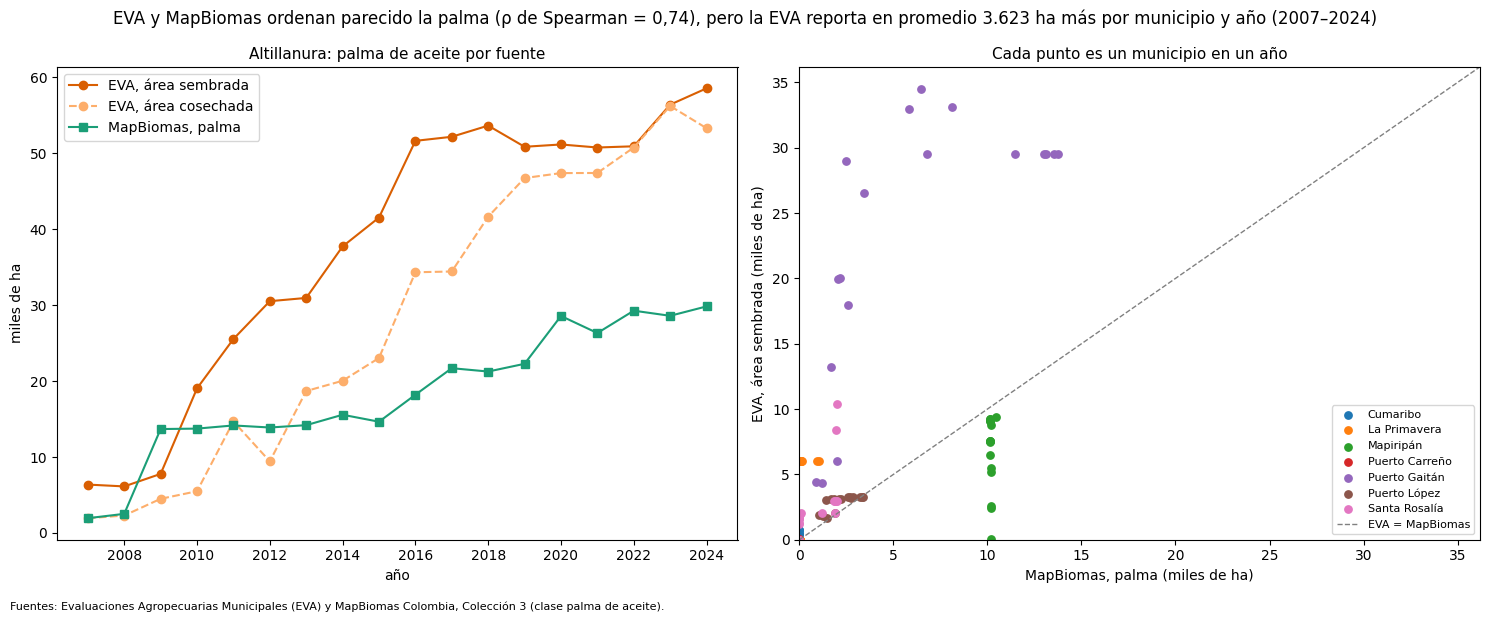

In [4]:
def coma0(valor):
    return coma(valor, 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(regional['anio'], regional['eva_sembrada_ha'] / 1e3, marker='o', color='#d95f02', label='EVA, área sembrada')
axes[0].plot(regional['anio'], regional['eva_cosechada_ha'] / 1e3, marker='o', linestyle='--', color='#fdae6b', label='EVA, área cosechada')
axes[0].plot(regional['anio'], regional['mapbiomas_ha'] / 1e3, marker='s', color='#1b9e77', label='MapBiomas, palma')
axes[0].set_ylabel('miles de ha')
axes[0].set_xlabel('año')
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_title('Altillanura: palma de aceite por fuente', fontsize=11)
axes[0].legend()

paleta = plt.get_cmap('tab10').colors
for i, (municipio, grupo) in enumerate(con_palma.groupby('municipio')):
    axes[1].scatter(grupo['mapbiomas_ha'] / 1e3, grupo['eva_sembrada_ha'] / 1e3, s=28, color=paleta[i], label=municipio.title())
tope = max(con_palma['mapbiomas_ha'].max(), con_palma['eva_sembrada_ha'].max()) / 1e3 * 1.05
axes[1].plot([0, tope], [0, tope], color='grey', linestyle='--', linewidth=1, label='EVA = MapBiomas')
axes[1].set_xlim(0, tope)
axes[1].set_ylim(0, tope)
axes[1].set_xlabel('MapBiomas, palma (miles de ha)')
axes[1].set_ylabel('EVA, área sembrada (miles de ha)')
axes[1].set_title('Cada punto es un municipio en un año', fontsize=11)
axes[1].legend(fontsize=8)

sentido = 'más' if GLOBAL['sesgo_medio_ha'] > 0 else 'menos'
fig.suptitle(f'EVA y MapBiomas ordenan parecido la palma (ρ de Spearman = {coma(GLOBAL["spearman"], 2)}), pero la EVA reporta en promedio '
             f'{coma0(abs(GLOBAL["sesgo_medio_ha"]))} ha {sentido} por municipio y año ({ANIO_0}–{ANIO_1})', fontsize=12)
fig.text(0.01, -0.02, 'Fuentes: Evaluaciones Agropecuarias Municipales (EVA) y MapBiomas Colombia, Colección 3 (clase palma de aceite).', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '31_palma_eva_vs_mapbiomas.png'), dpi=150, bbox_inches='tight')
plt.show()

## Límites
- La EVA se construye con reportes municipales y consensos regionales; MapBiomas detecta la cobertura desde imágenes de 30 m. Una plantación joven puede estar sembrada en la EVA años antes de que MapBiomas la vea como palma.
- En la EVA hay cifras que se repiten varios años seguidos, lo que sugiere reportes que no se actualizaron.
- Con pocos municipios con palma y menos de 20 años comunes, los valores p de Spearman dentro de cada municipio son poco estables.

## Resumen para el informe

In [5]:
print(f'Años comunes: {ANIO_0}–{ANIO_1}; {int(GLOBAL["n"])} municipio-año con palma en alguna fuente.')
print(f'Spearman municipio-año (EVA sembrada vs MapBiomas): {coma(GLOBAL["spearman"], 2)} (p = {GLOBAL["p_valor"]:.3g}); '
      f'serie regional: {coma(REGION["spearman"], 2)} (p = {REGION["p_valor"]:.3g}).')
print(f'Sesgo medio EVA − MapBiomas: {coma0(GLOBAL["sesgo_medio_ha"])} ha por municipio y año '
      f'({coma(GLOBAL["sesgo_relativo_pct"])} % del área de MapBiomas).')
for _, f in resumen.iloc[4:].iterrows():
    print(f'  {f.grupo.title()}: ρ = {coma(f.spearman, 2) if pd.notna(f.spearman) else "—"}, sesgo medio {coma0(f.sesgo_medio_ha)} ha (n = {int(f.n)})')

Años comunes: 2007–2024; 97 municipio-año con palma en alguna fuente.
Spearman municipio-año (EVA sembrada vs MapBiomas): 0,74 (p = 7.73e-18); serie regional: 0,89 (p = 7.28e-07).
Sesgo medio EVA − MapBiomas: 3.623 ha por municipio y año (106,3 % del área de MapBiomas).
  Cumaribo: ρ = —, sesgo medio 550 ha (n = 7)
  La Primavera: ρ = 0,87, sesgo medio 2.855 ha (n = 18)
  Mapiripán: ρ = -0,43, sesgo medio -3.473 ha (n = 16)
  Puerto Carreño: ρ = —, sesgo medio 35 ha (n = 2)
  Puerto Gaitán: ρ = 0,80, sesgo medio 17.128 ha (n = 18)
  Puerto López: ρ = 0,83, sesgo medio 686 ha (n = 18)
  Santa Rosalía: ρ = 0,85, sesgo medio 1.723 ha (n = 18)
